## Plan du notebook

1. Configuration et imports
2. Chargement des données
3. Visualisation du dataset
4. Définition de la tâche et des variables
5. Fonctions utilitaires
6. Baselines (scores à battre)
7. Entraînement des modèles
8. Réglage des hyperparamètres
9. Comparaison des modèles
10. Sélection du meilleur modèle (grille pondérée)
11. Évaluation finale sur le jeu de test
12. Interprétabilité et sauvegarde du modèle
13. Conclusion

**Règle de méthode :** le jeu de test n'est utilisé qu'une seule fois, à l'étape 11. Tous les choix (modèles, hyperparamètres) se font sur le train et la validation.

## 1. Configuration et imports

Objectif : charger les bibliothèques et fixer la graine aléatoire (`SEED = 42`) pour que les résultats soient reproductibles par toute l'équipe.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.1.1 | numpy 2.5.4


## 2. Chargement des données

Objectif : charger les trois fichiers `train.csv`, `val.csv`, `test.csv`.

- `train` (70 %) : apprentissage des modèles
- `val` (15 %) : réglage des hyperparamètres et comparaison
- `test` (15 %) : évaluation finale, utilisé une seule fois



In [2]:
train = pd.read_csv("../data/processed/train.csv", parse_dates=["datetime"])
val   = pd.read_csv("../data/processed/val.csv",   parse_dates=["datetime"])
test  = pd.read_csv("../data/processed/test.csv",  parse_dates=["datetime"])

print("train :", train.shape)
print("val   :", val.shape)
print("test  :", test.shape)

train : (24374, 14)
val   : (5223, 14)
test  : (5223, 14)


In [3]:
train.head()

,datetime,traffic_flow,speed_kmh,week_day,holidays,temp_celsius,wind_speed_kmh,precip_mm,weather_condition,hour,minute,is_weekend,traffic_flow_lag_1,traffic_flow_lag_3
0,2020-02-01 00:15:00,337,105.25,6,1,12.78,4.83,0.0,Fair,0,15,1,347.0,338.0
1,2020-02-01 00:20:00,302,106.70,6,1,12.78,4.83,0.0,Fair,0,20,1,337.0,360.0
2,2020-02-01 00:25:00,282,105.09,6,1,12.78,4.83,0.0,Fair,0,25,1,302.0,347.0
3,2020-02-01 00:30:00,302,106.54,6,1,12.78,4.83,0.0,Fair,0,30,1,282.0,337.0
4,2020-02-01 00:35:00,277,106.54,6,1,12.78,4.83,0.0,Fair,0,35,1,302.0,302.0


In [4]:
resume = pd.DataFrame({
    "lignes": [len(train), len(val), len(test)],
    "début": [train.datetime.min(), val.datetime.min(), test.datetime.min()],
    "fin": [train.datetime.max(), val.datetime.max(), test.datetime.max()],
    "débit moyen": [round(d.traffic_flow.mean(), 1) for d in (train, val, test)],
    "valeurs manquantes": [int(d.isna().sum().sum()) for d in (train, val, test)],
}, index=["train", "val", "test"])
resume

,lignes,début,fin,débit moyen,valeurs manquantes
train,24374,2020-02-01 00:15:00,2020-04-25 17:25:00,416.0,0
val,5223,2020-04-25 17:30:00,2020-05-13 20:40:00,377.6,0
test,5223,2020-05-13 20:45:00,2020-05-31 23:55:00,406.3,0


**Observation :** les trois jeux se suivent dans le temps et ne contiennent aucune valeur manquante. Le débit moyen de la validation (≈ 378) est plus bas que celui du train (≈ 416) : cela reflète la baisse du trafic liée à la COVID-19 en mars-avril 2020, que nous retrouverons dans les graphiques de la section 3.

## 3. Visualisation du dataset

Objectif : comprendre le comportement du trafic avant d'entraîner les modèles. Nous regardons l'évolution dans le temps, les rythmes journaliers et hebdomadaires, la distribution du débit, les corrélations et l'effet de la météo.

In [5]:
# Ajout d'une colonne "jeu" pour distinguer train / val / test dans les graphiques
train["jeu"], val["jeu"], test["jeu"] = "train", "val", "test"
full = pd.concat([train, val, test], ignore_index=True)

# Ordre des jours pour les graphiques (1 = lundi ... 7 = dimanche)
jours = {1: "Lun", 2: "Mar", 3: "Mer", 4: "Jeu", 5: "Ven", 6: "Sam", 7: "Dim"}

print(full.shape)

(34820, 15)


### 3.1 Évolution du débit dans le temps

Débit moyen par jour, avec les trois jeux en couleurs différentes. Ce graphique montre où tombent les coupures chronologiques et le changement de régime du trafic.

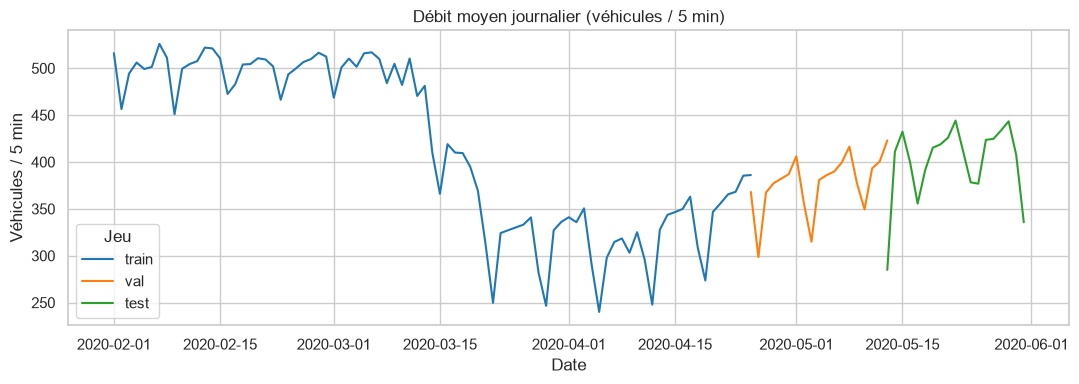

In [6]:
fig, ax = plt.subplots()
couleurs = {"train": "tab:blue", "val": "tab:orange", "test": "tab:green"}

for nom, c in couleurs.items():
    j = full[full["jeu"] == nom].set_index("datetime")["traffic_flow"].resample("D").mean()
    ax.plot(j.index, j.values, color=c, label=nom)

ax.set_title("Débit moyen journalier (véhicules / 5 min)")
ax.set_xlabel("Date")
ax.set_ylabel("Véhicules / 5 min")
ax.legend(title="Jeu")
plt.tight_layout()
plt.show()

**Observation :** le débit chute fortement entre février et avril 2020 (confinement lié à la COVID-19), puis remonte en mai. Le jeu d'entraînement contient donc deux régimes de trafic différents, la validation tombe dans la période creuse puis la reprise, et le test correspond à une reprise partielle. Les scores obtenus sur le test ne reflètent donc pas une année normale, et nous le préciserons dans la conclusion.

### 3.2 Profil horaire : semaine contre week-end

Débit moyen par heure de la journée, séparé entre jours de semaine et week-end. Ce graphique montre le rythme journalier du trafic et justifie l'usage de `hour` et `is_weekend` comme variables.

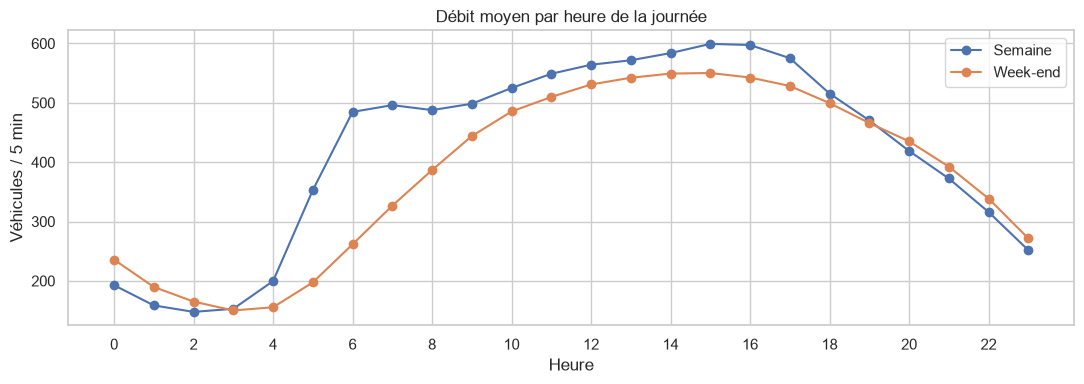

In [7]:
profil = full.groupby(["is_weekend", "hour"])["traffic_flow"].mean().unstack(0)
profil.columns = ["Semaine", "Week-end"]

ax = profil.plot(marker="o")
ax.set_title("Débit moyen par heure de la journée")
ax.set_xlabel("Heure")
ax.set_ylabel("Véhicules / 5 min")
ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()

**Observation :** les deux courbes ne se ressemblent pas. Complétez ici en regardant votre graphique : à quelle heure le débit est-il le plus bas la nuit, à quelle heure atteint-il son maximum en semaine, et en quoi le week-end diffère-t-il ?

Conclusion : le trafic suit un rythme journalier marqué qui dépend du type de jour, donc `hour` et `is_weekend` seront des variables importantes pour les modèles.

### 3.3 Carte de chaleur : jour de la semaine × heure

Débit moyen pour chaque combinaison jour de la semaine et heure. Ce graphique est l'un de ceux demandés dans le cahier des charges (page 2 du dashboard), et il montre d'un seul coup d'œil les heures de pointe.

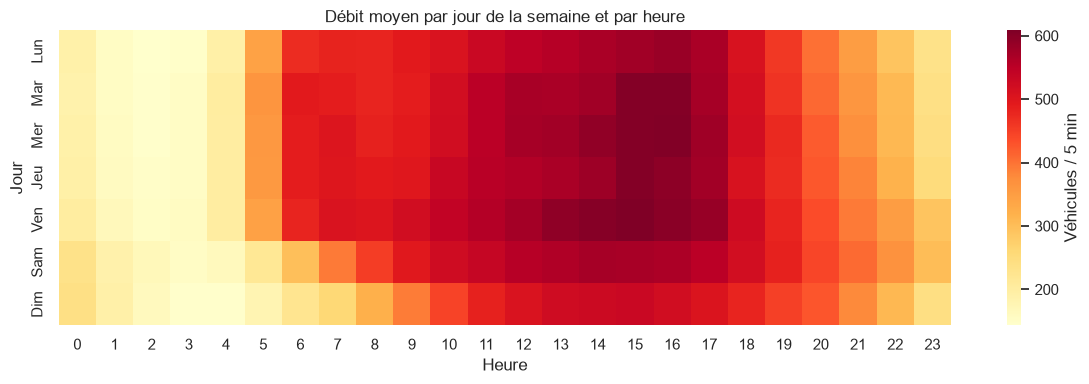

In [8]:
chaleur = full.pivot_table(index="week_day", columns="hour",
                           values="traffic_flow", aggfunc="mean")
chaleur.index = [jours[j] for j in chaleur.index]

plt.figure(figsize=(12, 4))
sns.heatmap(chaleur, cmap="YlOrRd", cbar_kws={"label": "Véhicules / 5 min"})
plt.title("Débit moyen par jour de la semaine et par heure")
plt.xlabel("Heure")
plt.ylabel("Jour")
plt.tight_layout()
plt.show()

**Observation :** (à compléter) Quelles plages horaires sont les plus foncées en semaine ? Le samedi et le dimanche ont-ils la même forme ? Repérez aussi les créneaux de nuit les plus calmes.

Conclusion : les heures de pointe se concentrent sur certains créneaux précis, ce qui confirme l'intérêt de variables temporelles pour prédire le trafic et pour adapter la durée des feux.

### 3.4 Distribution du débit

Histogramme des valeurs de `traffic_flow` (la variable à prédire) et statistiques descriptives. Il permet de voir si le débit est concentré autour d'une valeur ou réparti en plusieurs groupes.

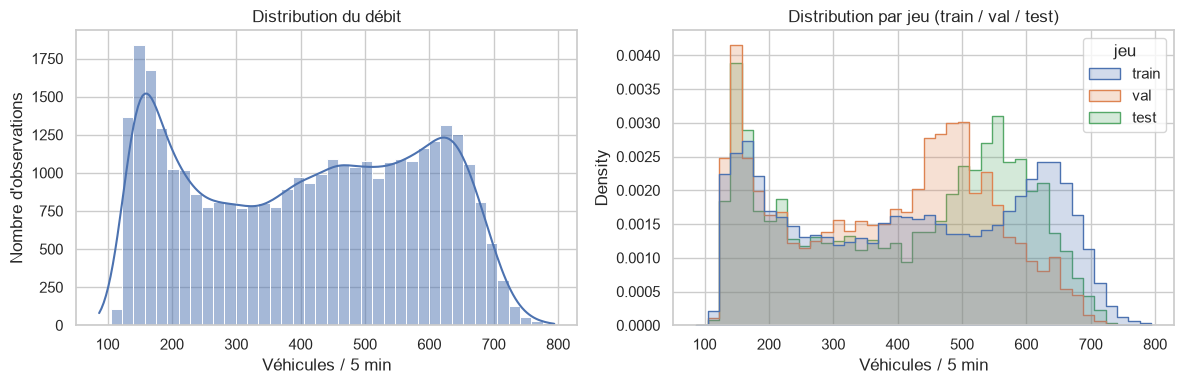

count    34820.0
mean       408.7
std        179.0
min         87.0
25%        237.0
50%        421.0
75%        568.0
max        794.0
Name: traffic_flow, dtype: float64

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(full["traffic_flow"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Distribution du débit")
axes[0].set_xlabel("Véhicules / 5 min")
axes[0].set_ylabel("Nombre d'observations")

sns.histplot(data=full, x="traffic_flow", hue="jeu", bins=40, element="step",
             stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("Distribution par jeu (train / val / test)")
axes[1].set_xlabel("Véhicules / 5 min")

plt.tight_layout()
plt.show()

full["traffic_flow"].describe().round(1)

**Observation :** (à compléter) La distribution a-t-elle une seule bosse ou plusieurs ? Les trois jeux ont-ils des distributions proches ou le val et le test sont-ils décalés par rapport au train ?

Conclusion : le débit varie de 87 à 794 véhicules par 5 minutes, avec une forte dispersion (écart-type d'environ 179). Une prédiction qui se contente de la moyenne globale (≈ 409) serait donc très imprécise.

### 3.5 Matrice de corrélation

Corrélation linéaire entre les variables numériques et le débit. Elle indique quelles variables sont liées à la cible, et lesquelles sont redondantes entre elles.

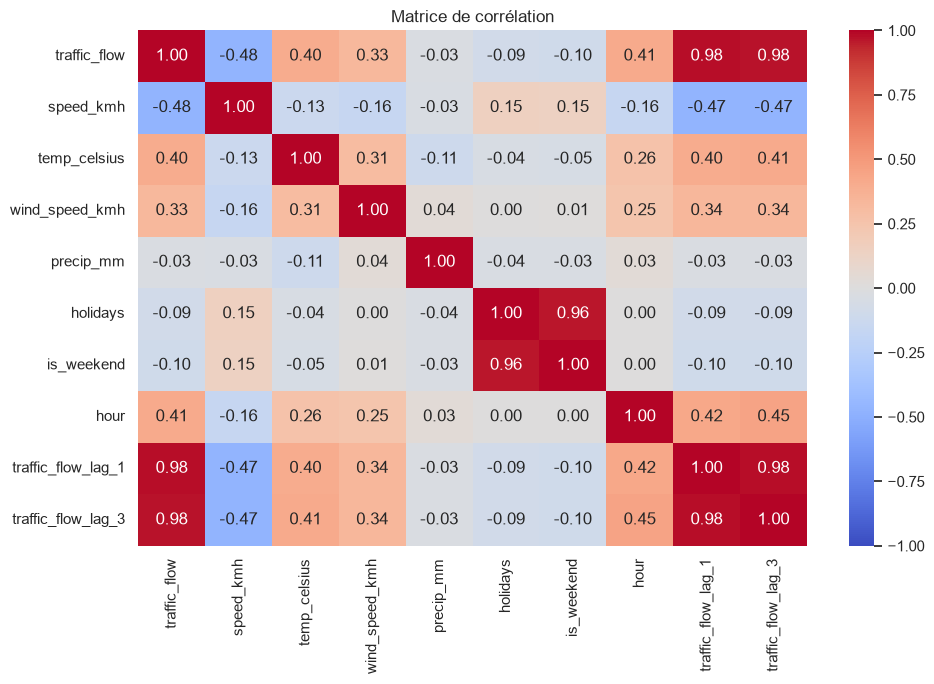

In [10]:
colonnes_corr = ["traffic_flow", "speed_kmh", "temp_celsius", "wind_speed_kmh",
                 "precip_mm", "holidays", "is_weekend", "hour",
                 "traffic_flow_lag_1", "traffic_flow_lag_3"]

plt.figure(figsize=(10, 7))
sns.heatmap(full[colonnes_corr].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()

In [11]:
full[colonnes_corr].corr()["traffic_flow"].drop("traffic_flow").sort_values(ascending=False).round(3)

traffic_flow_lag_1    0.984
traffic_flow_lag_3    0.975
hour                  0.412
temp_celsius          0.400
wind_speed_kmh        0.334
precip_mm            -0.029
holidays             -0.092
is_weekend           -0.097
speed_kmh            -0.475
Name: traffic_flow, dtype: float64

**Observation :**

- `traffic_flow_lag_1` est presque parfaitement corrélée au débit (≈ 0,98) : le trafic change peu en 5 minutes. Un modèle qui reprend simplement la valeur précédente sera déjà très bon, c'est pourquoi la baseline de **persistance** (section 6) est le vrai score à battre.
- `speed_kmh` est corrélée négativement au débit (≈ −0,48). Cependant, elle est mesurée **au même instant** que la cible : en situation réelle, on ne la connaît pas avant de prédire. Nous **l'excluons des variables d'entrée** pour éviter une fuite de données.
- `holidays` et `is_weekend` sont presque identiques (≈ 98 % de lignes égales) : elles apportent la même information.
- (à compléter) Que remarquez-vous pour `temp_celsius`, `wind_speed_kmh` et `precip_mm` ? Leur corrélation avec le débit est-elle forte ou faible ?

### 3.6 Effet de la météo sur le débit

Distribution du débit selon l'état du ciel (`weather_condition`), sous forme de boîtes à moustaches, avec le nombre d'observations de chaque catégorie. Certaines catégories sont très rares, donc il faut les interpréter avec prudence.

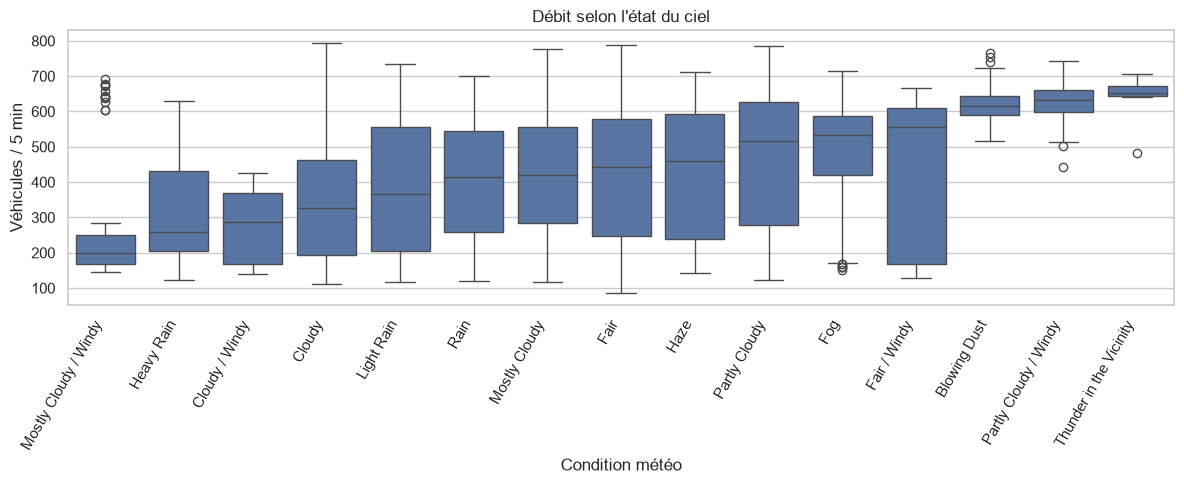

In [12]:
ordre = full.groupby("weather_condition")["traffic_flow"].median().sort_values().index

plt.figure(figsize=(12, 5))
sns.boxplot(data=full, x="weather_condition", y="traffic_flow", order=ordre)
plt.xticks(rotation=60, ha="right")
plt.title("Débit selon l'état du ciel")
plt.xlabel("Condition météo")
plt.ylabel("Véhicules / 5 min")
plt.tight_layout()
plt.show()

In [13]:
effectifs = (full.groupby(["weather_condition", "jeu"]).size().unstack(fill_value=0)
             .reindex(columns=["train", "val", "test"]))
effectifs["total"] = effectifs.sum(axis=1)
effectifs["débit moyen"] = full.groupby("weather_condition")["traffic_flow"].mean().round(1)
effectifs.sort_values("total", ascending=False)

jeu,train,val,test,total,débit moyen
weather_condition,,,,,
Fair,13634,4671,4431,22736,420.1
Cloudy,4464,312,492,5268,341.8
Mostly Cloudy,1944,96,132,2172,414.7
Partly Cloudy,1920,72,60,2052,461.5
Light Rain,1404,0,72,1476,384.6
Rain,432,0,24,456,403.8
Haze,120,60,12,192,431.1
Heavy Rain,120,0,0,120,310.3
Fair / Windy,72,0,0,72,432.2


**Observation :**

- Le débit moyen varie selon l'état du ciel, mais **ce graphique ne prouve pas que la météo cause ces écarts**. Les conditions rares (`Blowing Dust`, `Fog`...) n'apparaissent que sur quelques heures, souvent en février, quand le trafic était élevé, avant la chute liée à la COVID-19. La météo est donc mélangée avec la période.
- Certaines catégories n'existent que dans un seul jeu. Le prétraitement devra gérer les catégories inconnues (`OneHotEncoder(handle_unknown="ignore")`), sinon le modèle échouerait sur la validation ou le test.
- (à compléter) Quelles conditions ont le débit médian le plus bas et le plus haut ? Les catégories les plus fréquentes (`Fair`, `Cloudy`) se ressemblent-elles ?

Conclusion : la météo est une variable à garder, mais on ne doit pas s'attendre à ce qu'elle soit déterminante. L'heure, le jour et le niveau récent du trafic expliquent l'essentiel de la variation.

## 4. Tâche, données et variables

**Tâche :** régression. Nous prédisons `traffic_flow`, le nombre de véhicules sur les 5 prochaines minutes, à partir de l'historique récent du trafic, du calendrier et de la météo. Le notebook traite désormais **un seul scénario** : celui qui utilise l'historique récent, destiné à la régulation des feux en temps réel.

**Variables fournies au modèle** (19 colonnes brutes, définies dans `src/features.py`) :

| Groupe | Variables |
|---|---|
| Calendrier | `hour`, `minute`, `week_day`, `is_weekend`, `holidays` |
| Météo | `temp_celsius`, `wind_speed_kmh`, `precip_mm`, `weather_condition` |
| Historique du débit | débit 5, 10, 15, 30 et 60 minutes plus tôt (`traffic_flow_lag_1`, `_2`, `_3`, `_6`, `_12`), moyennes des 1 et 3 dernières heures (`flow_mean_12`, `flow_mean_36`), tendance `flow_diff` |
| Historique de la vitesse | vitesse 5 et 15 minutes plus tôt (`speed_lag_1`, `speed_lag_3`) |

**Règles anti-fuite de données :**
- la vitesse du même instant (`speed_kmh`) n'est **jamais** utilisée, seulement ses valeurs passées ;
- toutes les variables d'historique ne regardent que le passé ;
- le prétraitement (encodage cyclique de l'heure, normalisation, One-Hot) est dans la pipeline, ajusté sur le train seul ;
- le jeu de test n'est pas touché avant l'évaluation finale.

**Un scénario sans historique** (calendrier et météo seuls) avait été testé dans une première version : aucun modèle n'y battait la simple moyenne par heure, à cause du changement de régime du trafic. Il est écarté du livrable principal et traité comme piste d'amélioration dans la conclusion.

In [14]:
import sys, time
sys.path.append("..")   # permet d'importer le dossier src/ depuis le notebook

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

from src.features import *

SEED = 42                # graine aléatoire fixée pour toute l'équipe (reproductibilité)
np.random.seed(SEED)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)

# Les variables d'historique sont calculées sur la série complète (train, val, test)
train, val, test = charger_donnees_modele()

In [15]:
X_train, y_train = train[COLONNES_ENTREE], train[CIBLE]
X_val, y_val = val[COLONNES_ENTREE], val[CIBLE]

# Contrôles anti-fuite
assert CIBLE not in COLONNES_ENTREE and "speed_kmh" not in COLONNES_ENTREE

print("train :", X_train.shape, "|", train["datetime"].min(), "→", train["datetime"].max())
print("val   :", X_val.shape, "|", val["datetime"].min(), "→", val["datetime"].max())
print("test  :", test.shape, "(non utilisé avant la section 11)")
print("Colonnes d'entrée :", COLONNES_ENTREE)

train : (24338, 19) | 2020-02-01 03:15:00 → 2020-04-25 17:25:00
val   : (5223, 19) | 2020-04-25 17:30:00 → 2020-05-13 20:40:00
test  : (5223, 28) (non utilisé avant la section 11)
Colonnes d'entrée : ['hour', 'minute', 'week_day', 'holidays', 'is_weekend', 'temp_celsius', 'wind_speed_kmh', 'precip_mm', 'weather_condition', 'traffic_flow_lag_1', 'traffic_flow_lag_2', 'traffic_flow_lag_3', 'traffic_flow_lag_6', 'traffic_flow_lag_12', 'flow_mean_12', 'flow_mean_36', 'flow_diff', 'speed_lag_1', 'speed_lag_3']


## 5. Fonctions utilitaires

Les outils communs à tous les modèles, écrits une seule fois pour que la comparaison soit équitable.

**Stabilité mesurée par blocs.** La validation est découpée en **6 blocs consécutifs** d'environ 3 jours. Pour chaque modèle, nous calculons sa MAE dans chaque bloc, divisée par celle de la **persistance** sur le même bloc. Deux indicateurs en découlent :
- `blocs_gagnes` : nombre de blocs (sur 6) où le modèle bat la persistance ;
- `std_ratio` : variabilité de ce rapport d'un bloc à l'autre.

Cette mesure remplace l'écart-type de la validation croisée de la première version, qui reflétait surtout la difficulté des plis (le régime du trafic change) plutôt que la stabilité du modèle.

**Temps d'entraînement** : durée d'un seul ajustement du modèle final, sans la recherche d'hyperparamètres, pour que les modèles soient comparables.
**Temps d'inférence** : médiane de 200 prédictions d'une seule ligne, prétraitement compris, ce qui limite le bruit de mesure.

In [16]:
def evaluer(y_vrai, y_pred):
    """MAE, RMSE et R²."""
    return {"MAE": mean_absolute_error(y_vrai, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_vrai, y_pred))),
            "R2": r2_score(y_vrai, y_pred)}

NB_BLOCS = 6
blocs_val = np.array_split(np.arange(len(val)), NB_BLOCS)

def mae_par_bloc(y_vrai, y_pred):
    """MAE dans chacun des blocs consécutifs de la validation."""
    y_vrai, y_pred = np.asarray(y_vrai), np.asarray(y_pred)
    return np.array([np.abs(y_vrai[b] - y_pred[b]).mean() for b in blocs_val])

pred_persistance_val = X_val["traffic_flow_lag_1"].values
mae_blocs_persistance = mae_par_bloc(y_val, pred_persistance_val)
print("MAE de la persistance par bloc :", mae_blocs_persistance.round(1))

MAE de la persistance par bloc : [21.7 23.1 20.2 23.1 22.4 24.3]


In [17]:
def temps_inference_ms(pipe, X, n=200):
    """Médiane du temps de prédiction d'UNE ligne, en millisecondes."""
    ligne = X.iloc[[0]]
    durees = []
    for _ in range(n):
        t0 = time.perf_counter()
        pipe.predict(ligne)
        durees.append(time.perf_counter() - t0)
    return float(np.median(durees)) * 1000

resultats, modeles, predictions_val = [], {}, {}

def enregistrer(nom, pred_train, pred_val, y_fit, temps_fit=0.0, infer_ms=np.nan, params="", pipe=None):
    """Calcule les métriques d'un modèle et les ajoute (ou remplacent) dans `resultats`.

    Les prédictions de validation et la pipeline entraînée sont conservées
    (utiles pour les tests statistiques et pour le réentraînement final).
    """
    m_val, m_train = evaluer(y_val, pred_val), evaluer(y_fit, pred_train)
    ratio = mae_par_bloc(y_val, pred_val) / mae_blocs_persistance
    ligne = {"model": nom, "MAE": m_val["MAE"], "RMSE": m_val["RMSE"], "R2": m_val["R2"],
             "MAE_train": m_train["MAE"], "gap_MAE": m_val["MAE"] - m_train["MAE"],
             "blocs_gagnes": int((ratio < 1).sum()), "std_ratio": float(ratio.std()),
             "train_time": temps_fit, "infer_time_ms": infer_ms, "best_params": str(params)}
    resultats[:] = [r for r in resultats if r["model"] != nom]
    resultats.append(ligne)
    predictions_val[nom] = np.asarray(pred_val)
    if pipe is not None:
        modeles[nom] = pipe
    return ligne

In [18]:
def entrainer_et_evaluer(nom, modele, grille=None, normaliser=True, pas_echantillon=1, n_splits=3):
    """Entraîne un modèle (avec réglage optionnel) et enregistre son résultat sur la validation.

    grille : dict d'hyperparamètres, clés préfixées par 'modele__' (ex. {"modele__max_depth": [3, 5]}).
             Réglage par validation croisée TEMPORELLE sur le train, critère MAE.
    pas_echantillon : n pour n'utiliser qu'une ligne sur n du train (modèles très lents).
    """
    X_fit, y_fit = X_train.iloc[::pas_echantillon], y_train.iloc[::pas_echantillon]
    pipe, params = faire_pipeline(modele, normaliser), {}

    if grille:
        gs = GridSearchCV(pipe, grille, cv=TimeSeriesSplit(n_splits=n_splits),
                          scoring="neg_mean_absolute_error", n_jobs=-1)
        gs.fit(X_fit, y_fit)
        pipe, params = clone(gs.best_estimator_), gs.best_params_

    # Un seul ajustement chronométré (sans la recherche d'hyperparamètres)
    t0 = time.perf_counter()
    pipe.fit(X_fit, y_fit)
    temps_fit = time.perf_counter() - t0

    return enregistrer(nom, pipe.predict(X_fit), pipe.predict(X_val), y_fit, temps_fit,
                       temps_inference_ms(pipe, X_val), params, pipe)

## 6. Baselines : les scores à battre

Des repères simples, calculés sur le **train seul** puis évalués sur la validation. Un modèle n'a d'intérêt que s'il fait mieux qu'eux.

| Baseline | Principe |
|---|---|
| **Persistance** | prédire le débit d'il y a 5 minutes (`traffic_flow_lag_1`) |
| **Moyenne par heure** | débit moyen du train pour chaque couple (week-end ou non, heure) |
| **Moyenne globale** | toujours prédire la moyenne du train |

La persistance est la référence principale : le trafic change peu en 5 minutes, elle est donc difficile à battre.

In [19]:
COLONNES_AFFICHAGE = ["model", "MAE", "RMSE", "R2", "gap_MAE", "blocs_gagnes",
                      "std_ratio", "train_time", "infer_time_ms"]

def afficher(*noms):
    """Tableau des résultats enregistrés (tous les modèles, ou ceux dont on donne le nom)."""
    t = pd.DataFrame(resultats)
    if noms:
        t = t[t["model"].isin(noms)]
    return t[COLONNES_AFFICHAGE].round(3).reset_index(drop=True)

# Baseline 1 : persistance
enregistrer("persistance", X_train["traffic_flow_lag_1"].values, pred_persistance_val, y_train)

# Baseline 2 : moyenne par (week-end, heure), calculée sur le train uniquement
table_heure = train.groupby(["is_weekend", "hour"])["traffic_flow"].mean().rename("pred").reset_index()

def pred_moyenne_par_heure(X):
    cle = ["is_weekend", "hour"]
    return X[cle].merge(table_heure, on=cle, how="left")["pred"].fillna(y_train.mean()).values

enregistrer("moyenne_par_heure", pred_moyenne_par_heure(X_train), pred_moyenne_par_heure(X_val), y_train)

# Baseline 3 : moyenne globale du train
enregistrer("moyenne_globale", np.full(len(X_train), y_train.mean()),
            np.full(len(X_val), y_train.mean()), y_train)

afficher()

,model,MAE,RMSE,R2,gap_MAE,blocs_gagnes,std_ratio,train_time,infer_time_ms
0,persistance,22.469,31.288,0.960,-0.963,0,0.000,0.0,NaN
1,moyenne_par_heure,51.568,66.240,0.822,-35.515,0,0.460,0.0,NaN
2,moyenne_globale,136.533,161.764,-0.060,-24.960,0,0.191,0.0,NaN


## 7. Entraînement et réglage des modèles

Huit modèles de familles différentes, entraînés avec la **même fonction** (`entrainer_et_evaluer`), les mêmes données et les mêmes métriques.

**Réglage des hyperparamètres :** recherche sur une grille réduite, par validation croisée **temporelle** (3 plis, chaque pli s'entraîne sur le passé et se valide sur la période suivante), sur le train seul, avec la MAE comme critère. Le modèle retenu est ensuite évalué sur la validation. Le jeu de test n'est pas utilisé.

| Famille | Modèles | Normalisation |
|---|---|---|
| Linéaire | Régression linéaire | oui |
| Arbres | Decision Tree, Random Forest | non |
| Distance / marges | KNN, SVM | oui |
| Boosting | XGBoost, LightGBM | non |
| Réseau de neurones | MLP | oui |

Colonnes des tableaux : `MAE`, `RMSE`, `R2` (validation) ; `gap_MAE` = MAE de validation moins MAE d'entraînement (un écart très positif signale du surapprentissage) ; `blocs_gagnes` = nombre de blocs de validation (sur 6) où le modèle bat la persistance ; `std_ratio` = variabilité de ce rapport d'un bloc à l'autre ; `train_time` en secondes (un seul ajustement) ; `infer_time_ms` en millisecondes pour une prédiction.

### 7.1 Régression linéaire

Une combinaison linéaire des variables : le modèle le plus simple et le plus interprétable. Variables normalisées, pas d'hyperparamètre à régler.

In [20]:
from sklearn.linear_model import LinearRegression

entrainer_et_evaluer("regression_lineaire", LinearRegression(), normaliser=True)
afficher("regression_lineaire")

,model,MAE,RMSE,R2,gap_MAE,blocs_gagnes,std_ratio,train_time,infer_time_ms
0,regression_lineaire,19.415,27.182,0.97,-1.369,6,0.016,0.134,17.077


### 7.2 Decision Tree (arbre de décision)

Un arbre qui découpe les données par une suite de questions. Facile à lire, mais il surapprend si sa profondeur n'est pas limitée.

Grille : `max_depth` (3, 5, 8, 12, illimitée) et `min_samples_leaf` (1, 10, 50) : 15 combinaisons. Pas de normalisation.

In [21]:
from sklearn.tree import DecisionTreeRegressor

grille_dt = {"modele__max_depth": [3, 5, 8, 12, None],
             "modele__min_samples_leaf": [1, 10, 50]}

r = entrainer_et_evaluer("decision_tree", DecisionTreeRegressor(random_state=SEED),
                         grille=grille_dt, normaliser=False)
print("Hyperparamètres retenus :", r["best_params"])
afficher("decision_tree")

Hyperparamètres retenus : {'modele__max_depth': 8, 'modele__min_samples_leaf': 50}


,model,MAE,RMSE,R2,gap_MAE,blocs_gagnes,std_ratio,train_time,infer_time_ms
0,decision_tree,21.057,29.502,0.965,0.597,6,0.02,0.467,15.561


### 7.3 Random Forest (forêt aléatoire)

Un ensemble d'arbres entraînés sur des échantillons différents, dont on fait la moyenne. Plus stable qu'un arbre seul.

Grille : `n_estimators` (100, 200), `max_depth` (8, 12) et `min_samples_leaf` (1, 10) : 8 combinaisons. Pas de normalisation.

**Cette cellule est la plus longue du notebook** (de quelques minutes à une dizaine selon votre machine) : la forêt est réentraînée pour chaque combinaison et chaque pli. Le paramètre `n_jobs=1` dans la forêt est volontaire : la validation croisée utilise déjà tous les cœurs.

In [22]:
from sklearn.ensemble import RandomForestRegressor

grille_rf = {"modele__n_estimators": [100, 200],
             "modele__max_depth": [8, 12],
             "modele__min_samples_leaf": [1, 10]}

r = entrainer_et_evaluer("random_forest", RandomForestRegressor(random_state=SEED, n_jobs=1),
                         grille=grille_rf, normaliser=False)
print("Hyperparamètres retenus :", r["best_params"])
afficher("random_forest")

Hyperparamètres retenus : {'modele__max_depth': 12, 'modele__min_samples_leaf': 10, 'modele__n_estimators': 200}


,model,MAE,RMSE,R2,gap_MAE,blocs_gagnes,std_ratio,train_time,infer_time_ms
0,random_forest,19.169,27.224,0.97,2.995,6,0.017,68.202,52.917


### 7.4 KNN (k plus proches voisins)

Pour chaque observation, le modèle cherche les `k` observations les plus proches dans le train et fait la moyenne de leur débit. Il repose sur les distances entre variables : la normalisation est indispensable, et l'encodage cyclique de l'heure fait que 23 h et 0 h sont proches.

Grille : `n_neighbors` (5, 15, 30, 60, 100). Les voisins sont pondérés de façon uniforme : avec une pondération par la distance, chaque point du train serait son propre voisin à distance nulle, l'erreur d'entraînement tomberait à zéro et `gap_MAE` n'aurait plus de sens.

In [23]:
from sklearn.neighbors import KNeighborsRegressor

r = entrainer_et_evaluer("knn", KNeighborsRegressor(),
                         grille={"modele__n_neighbors": [5, 15, 30, 60, 100]}, normaliser=True)
print("Hyperparamètres retenus :", r["best_params"])
afficher("knn")

Hyperparamètres retenus : {'modele__n_neighbors': 30}


,model,MAE,RMSE,R2,gap_MAE,blocs_gagnes,std_ratio,train_time,infer_time_ms
0,knn,26.072,34.535,0.952,3.411,0,0.064,0.102,27.02


### 7.5 SVM (machine à vecteurs de support, SVR)

Un modèle qui cherche une courbe passant au plus près des points, avec une marge de tolérance. Variables et cible sont normalisées (la cible via `TransformedTargetRegressor`, car un débit de plusieurs centaines de véhicules déstabilise l'apprentissage).

**Précaution : le SVM est lent sur de gros volumes** (son temps de calcul croît environ avec le carré du nombre de lignes). Il est entraîné sur **une ligne sur trois** du train (≈ 8 100 lignes), en gardant l'ordre chronologique, avec des hyperparamètres fixés (`kernel="rbf"`, `C=10`) et sans recherche sur grille. La validation reste évaluée sur le jeu complet. Un score un peu moins bon pour le SVM peut venir en partie de ce choix.

In [24]:
from sklearn.svm import SVR
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler

svm = TransformedTargetRegressor(regressor=SVR(kernel="rbf", C=10), transformer=StandardScaler())
entrainer_et_evaluer("svm", svm, normaliser=True, pas_echantillon=3)
afficher("svm")

,model,MAE,RMSE,R2,gap_MAE,blocs_gagnes,std_ratio,train_time,infer_time_ms
0,svm,21.528,29.338,0.965,6.102,4,0.046,19.134,17.555


### 7.6 XGBoost

Un modèle de **boosting** : il construit des arbres les uns après les autres, chacun corrigeant les erreurs des précédents. Pas de normalisation.

Grille : `n_estimators` (100, 300), `max_depth` (3, 5), `learning_rate` (0,05 ; 0,1) : 8 combinaisons.

In [25]:
from xgboost import XGBRegressor

grille_xgb = {"modele__n_estimators": [100, 300],
              "modele__max_depth": [3, 5],
              "modele__learning_rate": [0.05, 0.1]}

r = entrainer_et_evaluer("xgboost", XGBRegressor(random_state=SEED, n_jobs=1),
                         grille=grille_xgb, normaliser=False)
print("Hyperparamètres retenus :", r["best_params"])
afficher("xgboost")

Hyperparamètres retenus : {'modele__learning_rate': 0.05, 'modele__max_depth': 3, 'modele__n_estimators': 300}


,model,MAE,RMSE,R2,gap_MAE,blocs_gagnes,std_ratio,train_time,infer_time_ms
0,xgboost,19.066,26.904,0.971,-0.313,6,0.015,2.489,15.929


### 7.7 LightGBM

Un second modèle de **boosting**, de la même famille que XGBoost mais construit feuille par feuille, en général plus rapide à entraîner. Pas de normalisation. Même grille que XGBoost, pour une comparaison équitable.

In [26]:
from lightgbm import LGBMRegressor

grille_lgbm = {"modele__n_estimators": [100, 300],
               "modele__max_depth": [3, 5],
               "modele__learning_rate": [0.05, 0.1]}

r = entrainer_et_evaluer("lightgbm", LGBMRegressor(random_state=SEED, n_jobs=1, verbose=-1),
                         grille=grille_lgbm, normaliser=False)
print("Hyperparamètres retenus :", r["best_params"])
afficher("lightgbm")

Hyperparamètres retenus : {'modele__learning_rate': 0.1, 'modele__max_depth': 5, 'modele__n_estimators': 100}


,model,MAE,RMSE,R2,gap_MAE,blocs_gagnes,std_ratio,train_time,infer_time_ms
0,lightgbm,18.871,26.674,0.971,0.434,6,0.013,0.713,15.698


### 7.8 MLP (réseau de neurones)

Un réseau à une ou deux couches cachées qui apprend des relations non linéaires. Variables et cible sont normalisées. L'entraînement s'arrête quand la performance ne progresse plus (`early_stopping`).

Grille : `hidden_layer_sizes` (une couche de 32 neurones, ou deux couches de 64 et 32) et `alpha` (0,0001 ; 0,01 ; 0,1), la régularisation qui limite le surapprentissage : 6 combinaisons. Les préfixes des paramètres sont `modele__regressor__` car le réseau est enveloppé dans `TransformedTargetRegressor`.

In [27]:
import warnings
warnings.filterwarnings("ignore")   # masque les avertissements de convergence du MLP

from sklearn.neural_network import MLPRegressor

mlp = TransformedTargetRegressor(
    regressor=MLPRegressor(early_stopping=True, max_iter=300, random_state=SEED),
    transformer=StandardScaler())

grille_mlp = {"modele__regressor__hidden_layer_sizes": [(32,), (64, 32)],
              "modele__regressor__alpha": [0.0001, 0.01, 0.1]}

r = entrainer_et_evaluer("mlp", mlp, grille=grille_mlp, normaliser=True)
print("Hyperparamètres retenus :", r["best_params"])
afficher("mlp")

Hyperparamètres retenus : {'modele__regressor__alpha': 0.1, 'modele__regressor__hidden_layer_sizes': (64, 32)}


,model,MAE,RMSE,R2,gap_MAE,blocs_gagnes,std_ratio,train_time,infer_time_ms
0,mlp,19.102,26.613,0.971,-0.345,6,0.021,6.441,17.075


## 8. Comparaison des modèles

Objectif : réunir les résultats des 8 modèles et des 3 baselines (sur la **validation**), et les visualiser. Le choix du modèle se fera à la section 9, avec la grille pondérée du cahier des charges.

Trois vues :
- le **tableau classé par MAE** ;
- les **graphiques de MAE et de R²** ;
- une **carte de chaleur par bloc de validation**, qui montre si un modèle bat la persistance de façon régulière ou seulement en moyenne.

### 8.1 Tableau comparatif

Tous les modèles et baselines, classés de la MAE la plus basse à la plus haute. `type` distingue les baselines des modèles.

In [28]:
tableau = pd.DataFrame(resultats)
baselines = ["persistance", "moyenne_par_heure", "moyenne_globale"]
tableau["type"] = np.where(tableau["model"].isin(baselines), "baseline", "modèle")

classement = tableau.sort_values("MAE").reset_index(drop=True)
classement.index = classement.index + 1
classement.index.name = "rang"
classement[["model", "type"] + COLONNES_AFFICHAGE[1:]].round(3)

,model,type,MAE,RMSE,R2,gap_MAE,blocs_gagnes,std_ratio,train_time,infer_time_ms
rang,,,,,,,,,,
1,lightgbm,modèle,18.871,26.674,0.971,0.434,6,0.013,0.713,15.698
2,xgboost,modèle,19.066,26.904,0.971,-0.313,6,0.015,2.489,15.929
3,mlp,modèle,19.102,26.613,0.971,-0.345,6,0.021,6.441,17.075
4,random_forest,modèle,19.169,27.224,0.970,2.995,6,0.017,68.202,52.917
5,regression_lineaire,modèle,19.415,27.182,0.970,-1.369,6,0.016,0.134,17.077
6,decision_tree,modèle,21.057,29.502,0.965,0.597,6,0.020,0.467,15.561
7,svm,modèle,21.528,29.338,0.965,6.102,4,0.046,19.134,17.555
8,persistance,baseline,22.469,31.288,0.960,-0.963,0,0.000,0.000,NaN
9,knn,modèle,26.072,34.535,0.952,3.411,0,0.064,0.102,27.020


### 8.2 MAE et R²

À gauche, la MAE de tous les modèles (baselines en gris) avec la persistance en rouge : une barre plus longue que la ligne rouge signifie que le modèle fait **moins bien** que cette règle simple. À droite, le R² des modèles seuls.

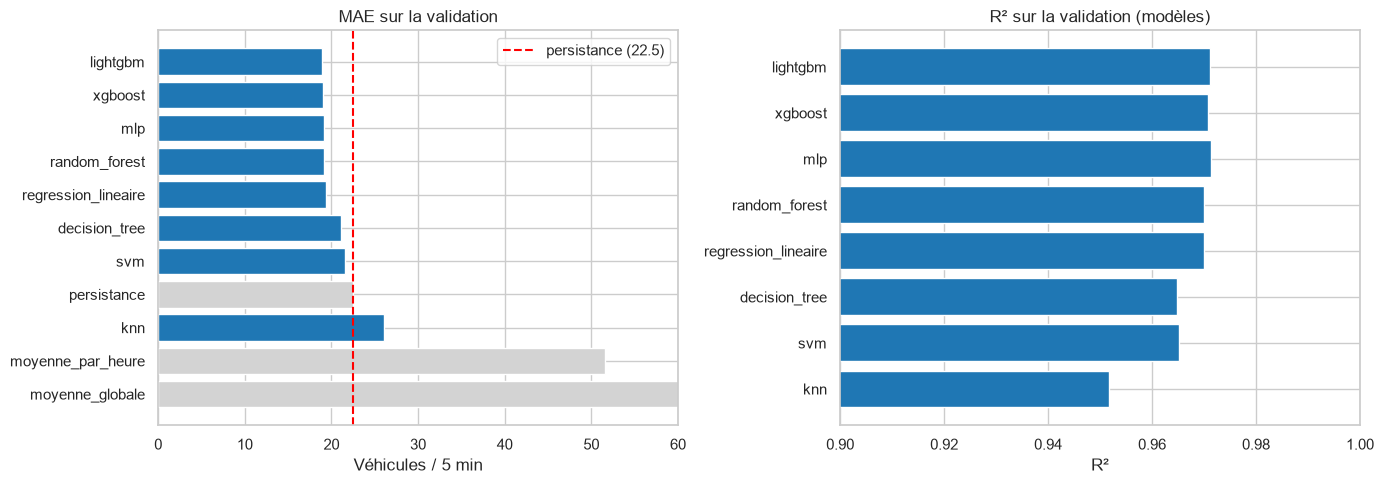

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

t = tableau.sort_values("MAE", ascending=False)
couleurs = ["lightgrey" if ty == "baseline" else "tab:blue" for ty in t["type"]]
axes[0].barh(t["model"], t["MAE"], color=couleurs)
mae_pers = tableau.loc[tableau["model"] == "persistance", "MAE"].iloc[0]
axes[0].axvline(mae_pers, color="red", linestyle="--", label=f"persistance ({mae_pers:.1f})")
axes[0].set_xlim(0, 60)
axes[0].set_title("MAE sur la validation")
axes[0].set_xlabel("Véhicules / 5 min")
axes[0].legend()

m = tableau[tableau["type"] == "modèle"].sort_values("MAE", ascending=False)
axes[1].barh(m["model"], m["R2"], color="tab:blue")
axes[1].set_xlim(0.9, 1.0)
axes[1].set_title("R² sur la validation (modèles)")
axes[1].set_xlabel("R²")

plt.tight_layout()
plt.show()

### 8.3 Régularité : rapport à la persistance par bloc

Pour chaque modèle et chacun des 6 blocs de la validation (environ 3 jours), la MAE du modèle divisée par celle de la persistance. Une valeur **inférieure à 1** (vert) signifie que le modèle fait mieux que la persistance dans ce bloc ; supérieure à 1 (rouge), moins bien. Cette vue montre si un gain moyen est régulier ou provient d'une seule période.

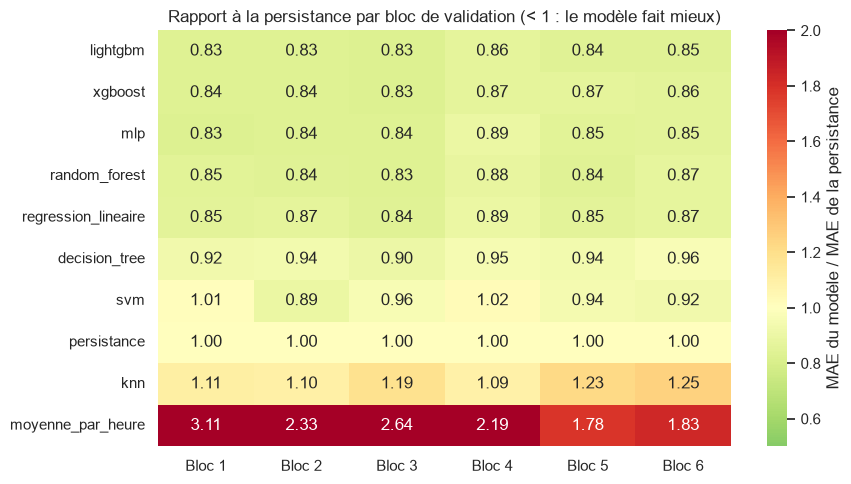

In [30]:
noms_modeles = [n for n in tableau.sort_values("MAE")["model"]
                if n in predictions_val and n != "moyenne_globale"]
ratios = pd.DataFrame(
    {n: mae_par_bloc(y_val, predictions_val[n]) / mae_blocs_persistance for n in noms_modeles},
    index=[f"Bloc {i + 1}" for i in range(NB_BLOCS)]).T

plt.figure(figsize=(9, 5))
sns.heatmap(ratios, annot=True, fmt=".2f", cmap="RdYlGn_r", center=1, vmin=0.5, vmax=2.0,
            cbar_kws={"label": "MAE du modèle / MAE de la persistance"})
plt.title("Rapport à la persistance par bloc de validation (< 1 : le modèle fait mieux)")
plt.tight_layout()
plt.show()

## 9. Sélection du meilleur modèle

Objectif : choisir **un modèle de façon objective**, avec la grille pondérée du cahier des charges (section 6.3). La sélection porte sur les 8 modèles ; les baselines servent de repère.

| Critère | Poids | Sous-score (entre 0 et 1) |
|---|---|---|
| Performance | 40 % | MAE du meilleur modèle divisée par la MAE du modèle |
| Généralisation | 20 % | 1 moins l'écart absolu `gap_MAE` rapporté à la MAE |
| Robustesse | 15 % | part des blocs gagnés contre la persistance × (1 − `std_ratio`) |
| Temps d'inférence | 15 % | 1 − log₁₀(ms) / 3 : 1 ms donne 1, 1 000 ms (limite du cahier des charges) donne 0 |
| Interprétabilité | 5 % | note qualitative (voir ci-dessous) |
| Temps d'entraînement | 5 % | 1 − log₁₀(s) / 3 : 1 s ou moins donne 1, 1 000 s donne 0 |

Le cahier des charges regroupe « interprétabilité et temps d'entraînement » en un critère de 10 % ; nous le séparons en deux moitiés égales.

**Améliorations par rapport à la première version :**
- les sous-scores ne dépendent plus d'une normalisation min-max, trop sensible aux valeurs extrêmes (KNN, SVM) ;
- la robustesse utilise les blocs de validation, plus fiable que l'écart-type de la validation croisée (qui reflétait surtout la difficulté des plis) ;
- les temps sont comparés à une échelle logarithmique : une différence de quelques millisecondes ne pèse presque rien, contrairement à un facteur dix.

**Choix de méthode :**
- la performance est mesurée sur la **validation**, jamais sur le test ;
- la note d'interprétabilité est un **jugement**, pas une mesure : régression linéaire 1,0, Decision Tree 0,9, Random Forest, XGBoost et LightGBM 0,5, KNN 0,3, SVM 0,2, MLP 0,1 ;
- une **analyse de sensibilité** vérifie ensuite que le classement ne dépend pas trop des poids, et des **tests statistiques** indiquent si les écarts de MAE entre modèles sont réels ou dus au hasard.

In [31]:
poids = {"performance": 0.40, "generalisation": 0.20, "inference": 0.15,
         "robustesse": 0.15, "interpretabilite": 0.05, "temps_entrainement": 0.05}
assert abs(sum(poids.values()) - 1) < 1e-9, "Les poids doivent sommer à 1"

interpretabilite = {"regression_lineaire": 1.0, "decision_tree": 0.9, "random_forest": 0.5,
                    "xgboost": 0.5, "lightgbm": 0.5, "knn": 0.3, "svm": 0.2, "mlp": 0.1}

def calculer_scores(tab, poids=poids):
    """Score pondéré (0 à 100) des 8 modèles. Chaque sous-score est compris entre 0 et 1."""
    d = tab[tab["type"] == "modèle"].set_index("model").copy()
    d["s_performance"] = d["MAE"].min() / d["MAE"]
    d["s_generalisation"] = 1 - np.minimum(d["gap_MAE"].abs() / d["MAE"], 1)
    d["s_robustesse"] = (d["blocs_gagnes"] / NB_BLOCS) * (1 - np.minimum(d["std_ratio"], 1))
    d["s_inference"] = (1 - np.log10(np.maximum(d["infer_time_ms"], 1)) / 3).clip(0, 1)
    d["s_interpretabilite"] = pd.Series(interpretabilite)
    d["s_temps_entrainement"] = (1 - np.log10(np.maximum(d["train_time"], 1)) / 3).clip(0, 1)
    d["score"] = 100 * sum(poids[k] * d["s_" + k] for k in poids)
    d = d.sort_values("score", ascending=False)
    d.insert(0, "rang", range(1, len(d) + 1))
    return d

scores = calculer_scores(tableau)
sous_scores = ["s_performance", "s_generalisation", "s_robustesse", "s_inference",
               "s_interpretabilite", "s_temps_entrainement"]
scores[["rang", "MAE"] + sous_scores + ["score"]].round(3)

,rang,MAE,s_performance,s_generalisation,s_robustesse,s_inference,s_interpretabilite,s_temps_entrainement,score
model,,,,,,,,,
regression_lineaire,1,19.415,0.972,0.930,0.984,0.589,1.0,1.000,91.063
lightgbm,2,18.871,1.000,0.977,0.987,0.601,0.5,1.000,90.861
xgboost,3,19.066,0.990,0.984,0.985,0.599,0.5,0.868,89.861
decision_tree,4,21.057,0.896,0.972,0.980,0.603,0.9,1.000,88.526
mlp,5,19.102,0.988,0.982,0.979,0.589,0.1,0.730,86.825
random_forest,6,19.169,0.984,0.844,0.983,0.425,0.5,0.389,81.830
svm,7,21.528,0.877,0.717,0.636,0.585,0.2,0.573,71.577
knn,8,26.072,0.724,0.869,0.000,0.523,0.3,1.000,60.677


### 9.2 Analyse de sensibilité aux poids

Les poids de la grille sont une convention. Nous recalculons le classement avec des pondérations alternatives pour voir si le premier modèle change.

| Variante | Idée |
|---|---|
| Sans temps d'inférence | ses écarts (quelques millisecondes) sont en partie du bruit de mesure |
| Performance renforcée | la MAE pèse 60 % |
| Interprétabilité renforcée | l'interprétabilité pèse 20 % (usage où l'on doit expliquer les décisions) |

In [32]:
variantes = {
    "Pondération du cahier des charges": poids,
    "Sans temps d'inférence": {"performance": 0.40/0.85, "generalisation": 0.20/0.85, "inference": 0.0,
                               "robustesse": 0.15/0.85, "interpretabilite": 0.05/0.85,
                               "temps_entrainement": 0.05/0.85},
    "Performance renforcée (60 %)": {"performance": 0.60, "generalisation": 0.10, "inference": 0.10,
                                     "robustesse": 0.10, "interpretabilite": 0.05, "temps_entrainement": 0.05},
    "Interprétabilité renforcée (20 %)": {"performance": 0.35, "generalisation": 0.15, "inference": 0.10,
                                          "robustesse": 0.10, "interpretabilite": 0.20, "temps_entrainement": 0.10},
}
sensibilite = {nom: ", ".join(calculer_scores(tableau, w).index[:3]) for nom, w in variantes.items()}
pd.DataFrame({"Top 3": sensibilite})

,Top 3
Pondération du cahier des charges,"regression_lineaire, lightgbm, xgboost"
Sans temps d'inférence,"regression_lineaire, lightgbm, xgboost"
Performance renforcée (60 %),"regression_lineaire, lightgbm, xgboost"
Interprétabilité renforcée (20 %),"regression_lineaire, decision_tree, lightgbm"


### 9.3 Les écarts de MAE sont-ils réels ?

Une MAE de 18,9 contre 19,1 est-elle une vraie différence ou du hasard ? Nous comparons les modèles deux à deux avec un **bootstrap apparié par blocs d'une journée** : on tire au hasard des journées entières de la validation, on recalcule l'écart de MAE, et on répète 2 000 fois. L'intervalle de confiance à 95 % donne la plage plausible de l'écart. Si elle **ne contient pas 0**, l'écart est jugé significatif.

On rééchantillonne des journées et non des lignes isolées, car les erreurs de pas de temps voisins sont corrélées : traiter chaque ligne comme indépendante rendrait les intervalles trop étroits.

Un écart « significatif » peut quand même être **trop petit pour compter en pratique** : on regarde donc aussi sa taille.

In [33]:
def difference_mae(nom_a, nom_b, n_rep=2000, taille_bloc=288):
    """Écart de MAE (a − b) avec intervalle de confiance à 95 %, bootstrap apparié par blocs d'une journée."""
    ea = np.abs(y_val.values - predictions_val[nom_a])
    eb = np.abs(y_val.values - predictions_val[nom_b])
    rng = np.random.default_rng(SEED)
    n, nb = len(ea), len(ea) // taille_bloc
    deplacements = np.arange(taille_bloc)
    ecarts = np.empty(n_rep)
    for i in range(n_rep):
        debuts = rng.integers(0, n - taille_bloc, nb)
        idx = (debuts[:, None] + deplacements).ravel()
        ecarts[i] = ea[idx].mean() - eb[idx].mean()
    bas, haut = np.percentile(ecarts, [2.5, 97.5])
    return ea.mean() - eb.mean(), bas, haut

meilleur = scores.index[0]
lignes = []
for nom in scores.index:
    for ref in ["persistance", meilleur]:
        if nom == ref:
            continue
        ecart, bas, haut = difference_mae(nom, ref)
        lignes.append({"modèle": nom, "référence": ref, "écart MAE": ecart,
                       "IC95 bas": bas, "IC95 haut": haut, "significatif": (bas > 0) or (haut < 0)})
tests = pd.DataFrame(lignes)
tests.round(2)

,modèle,référence,écart MAE,IC95 bas,IC95 haut,significatif
0,regression_lineaire,persistance,-3.05,-3.37,-2.63,True
1,lightgbm,persistance,-3.60,-3.93,-3.21,True
2,lightgbm,regression_lineaire,-0.54,-0.71,-0.38,True
3,xgboost,persistance,-3.40,-3.70,-3.05,True
4,xgboost,regression_lineaire,-0.35,-0.54,-0.13,True
5,decision_tree,persistance,-1.41,-1.71,-1.12,True
6,decision_tree,regression_lineaire,1.64,1.29,1.94,True
7,mlp,persistance,-3.37,-3.71,-2.93,True
8,mlp,regression_lineaire,-0.31,-0.48,-0.15,True
9,random_forest,persistance,-3.30,-3.65,-2.96,True


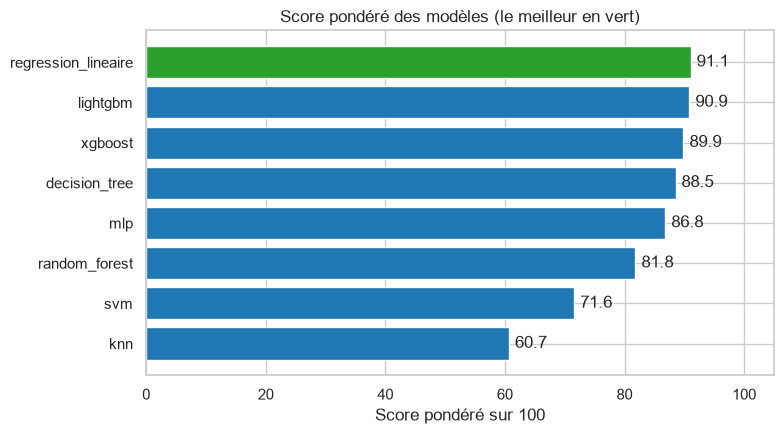

In [34]:
t = scores.sort_values("score")
couleurs = ["tab:green" if m == meilleur else "tab:blue" for m in t.index]

plt.figure(figsize=(8, 4.5))
plt.barh(t.index, t["score"], color=couleurs)
for i, v in enumerate(t["score"]):
    plt.text(v + 1, i, f"{v:.1f}", va="center")
plt.xlim(0, 105)
plt.xlabel("Score pondéré sur 100")
plt.title("Score pondéré des modèles (le meilleur en vert)")
plt.tight_layout()
plt.show()

In [35]:
print("Meilleur selon la grille :", meilleur)
display(scores[["rang", "MAE", "s_performance", "s_generalisation", "s_robustesse",
                "s_inference", "s_interpretabilite", "s_temps_entrainement", "score"]].round(3))
print(pd.DataFrame({"Top 3": sensibilite}).to_string())
print(tableau.set_index("model")[["train_time", "infer_time_ms"]].round(2).to_string())

Meilleur selon la grille : regression_lineaire


,rang,MAE,s_performance,s_generalisation,s_robustesse,s_inference,s_interpretabilite,s_temps_entrainement,score
model,,,,,,,,,
regression_lineaire,1,19.415,0.972,0.930,0.984,0.589,1.0,1.000,91.063
lightgbm,2,18.871,1.000,0.977,0.987,0.601,0.5,1.000,90.861
xgboost,3,19.066,0.990,0.984,0.985,0.599,0.5,0.868,89.861
decision_tree,4,21.057,0.896,0.972,0.980,0.603,0.9,1.000,88.526
mlp,5,19.102,0.988,0.982,0.979,0.589,0.1,0.730,86.825
random_forest,6,19.169,0.984,0.844,0.983,0.425,0.5,0.389,81.830
svm,7,21.528,0.877,0.717,0.636,0.585,0.2,0.573,71.577
knn,8,26.072,0.724,0.869,0.000,0.523,0.3,1.000,60.677


                                                                          Top 3
Pondération du cahier des charges        regression_lineaire, lightgbm, xgboost
Sans temps d'inférence                   regression_lineaire, lightgbm, xgboost
Performance renforcée (60 %)             regression_lineaire, lightgbm, xgboost
Interprétabilité renforcée (20 %)  regression_lineaire, decision_tree, lightgbm
                     train_time  infer_time_ms
model                                         
persistance                0.00            NaN
moyenne_par_heure          0.00            NaN
moyenne_globale            0.00            NaN
regression_lineaire        0.13          17.08
decision_tree              0.47          15.56
random_forest             68.20          52.92
knn                        0.10          27.02
svm                       19.13          17.55
xgboost                    2.49          15.93
lightgbm                   0.71          15.70
mlp                        6.44     

### 9.5 Conclusion de la sélection

**Tous les modèles sauf un battent la persistance, de façon significative.** Sur la validation, la MAE baisse de 4,2 % (SVM) à 16,0 % (LightGBM) par rapport à la persistance (22,47). Seul le KNN fait moins bien (+16,0 %) : il ne bat la persistance dans aucun des 6 blocs de validation.

**Les cinq meilleurs modèles sont très proches.** LightGBM (18,87), XGBoost (19,07), MLP (19,10), Random Forest (19,17) et régression linéaire (19,42) tiennent dans un écart de 0,54 véhicule par 5 minutes, soit environ 3 %. Le test par bootstrap montre que ces écarts sont statistiquement réels : par exemple, LightGBM fait mieux que la régression linéaire de 0,54 véhicule, intervalle de confiance à 95 % [−0,71 ; −0,38]. Mais ils sont minuscules en pratique, de l'ordre de 0,1 % du débit moyen (environ 400 véhicules par 5 minutes).

**La grille pondérée désigne la régression linéaire** (score ≈ 91,1), devant LightGBM (≈ 90,2) et XGBoost (≈ 89,9), suivis du Decision Tree, du MLP, du Random Forest, du SVM et du KNN. Elle reste première dans les quatre pondérations testées (cahier des charges, sans temps d'inférence, performance renforcée à 60 %, interprétabilité renforcée) ; LightGBM et XGBoost complètent le podium dans les trois premières, le Decision Tree dans la dernière.

**Nous retenons donc la régression linéaire.** Ses arguments :
- sa MAE est à moins de 3 % de celle du meilleur modèle, et elle bat la persistance dans les 6 blocs de validation (gain de 13,6 %) ;
- elle ne surapprend pas (`gap_MAE` ≈ −1,4) et sa variabilité d'un bloc à l'autre est très faible (`std_ratio` ≈ 0,016) ;
- c'est le modèle le plus simple et le plus interprétable : ses coefficients se lisent directement ;
- elle s'entraîne en environ 0,1 s et n'ajoute aucune dépendance au dashboard et à la simulation.

**Réserves à connaître :**
- La marge de la régression linéaire sur LightGBM est étroite (moins de 1 point sur 100) et dépend des temps d'inférence mesurés sur la machine (de l'ordre de 16 ms contre 21 ms) : ces temps sont du bruit de mesure plus qu'une vraie différence entre les modèles. Avec une autre machine, LightGBM aurait pu passer devant.
- **LightGBM est une alternative légèrement plus précise** (MAE inférieure de 0,54, soit 2,8 %). Si l'équipe préfère la précision à la simplicité, c'est le choix de remplacement, au prix d'un modèle moins lisible. Le critère retenu ici est celui défini à l'avance par le cahier des charges.
- Le Random Forest est le plus lent (environ 68 s d'entraînement, 53 ms d'inférence, soit encore bien en dessous de la limite d'une seconde) pour un résultat qui n'est pas meilleur que celui des boosting.
- Le SVM a été entraîné sur un tiers du train et ne bat la persistance que dans 4 blocs sur 6 ; son résultat n'est pas strictement comparable.

**Apport des nouvelles variables.** Par rapport à la première version du notebook, l'ajout de l'historique plus long (10, 30 et 60 minutes), des moyennes mobiles et de la vitesse passée fait baisser la MAE de validation de la régression linéaire de 20,38 à 19,42 et celle de LightGBM de 20,08 à 18,87.

**Limites.**
- La validation ne couvre que 18 jours, dans une période de trafic plus bas que le train.
- La note d'interprétabilité est un jugement, et les poids de la grille sont une convention : le classement est stable sur les quatre pondérations testées, sans que cela garantisse qu'il le serait pour toutes.
- Les grilles d'hyperparamètres sont réduites.
- Le jeu de test n'est pas encore utilisé dans cette version du notebook.

## 10. Évaluation finale sur le jeu de test

Le modèle retenu est la **régression linéaire**. Il est **réentraîné sur train et validation réunis** (davantage de données récentes, donc plus proches du régime actuel du trafic), avec les mêmes paramètres, puis évalué **une seule fois** sur le test. Sa sortie est bornée à 0 (un débit ne peut pas être négatif). Pour référence, nous évaluons aussi la persistance et la moyenne par heure, qui n'interviennent dans aucun choix.

**Remarque d'honnêteté :** le test avait déjà été consulté une fois dans une version précédente de ce notebook. Cette évaluation est la définitive, mais le test n'est pas vierge ; le rapport doit le mentionner.

In [36]:
assert "regression_lineaire" in modeles, "Relancez la cellule 7.1 (régression linéaire)"

X_tv, y_tv = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
X_test, y_test = test[COLONNES_ENTREE], test[CIBLE]

modele_final = RegresseurBorne(clone(modeles["regression_lineaire"]), minimum=0.0).fit(X_tv, y_tv)
pred_test = modele_final.predict(X_test)              # seule utilisation du test pour le modèle final
pred_pers_test = X_test["traffic_flow_lag_1"].values
pred_mph_test = pred_moyenne_par_heure(X_test)

def resume_test(nom, p):
    e = y_test.values - p
    m = evaluer(y_test, p)
    return {"modèle": nom, "MAE": m["MAE"], "RMSE": m["RMSE"], "R2": m["R2"],
            "WAPE_pct": np.abs(e).sum() / y_test.values.sum() * 100, "biais": e.mean(),
            "gain_vs_persistance_pct": (1 - np.abs(e).mean() / np.abs(y_test.values - pred_pers_test).mean()) * 100}

resultats_test = pd.DataFrame([resume_test("regression_lineaire (modèle final)", pred_test),
                               resume_test("persistance", pred_pers_test),
                               resume_test("moyenne_par_heure", pred_mph_test)])
resultats_test.round(3)

,modèle,MAE,RMSE,R2,WAPE_pct,biais,gain_vs_persistance_pct
0,regression_lineaire (modèle final),19.991,27.922,0.974,4.920,0.593,13.119
1,persistance,23.009,31.619,0.967,5.663,-0.036,0.000
2,moyenne_par_heure,45.327,60.703,0.877,11.156,-7.398,-96.995


### 10.2 Écart avec la persistance et régularité sur le test

Même méthode qu'en validation : bootstrap apparié par blocs d'une journée (2 000 tirages) pour l'intervalle de confiance de l'écart de MAE, et nombre de blocs du test (sur 6) où le modèle bat la persistance.

In [38]:
def ic_bootstrap(err_a, err_b, n_rep=2000, taille_bloc=288):
    """Écart de MAE (a − b) et intervalle de confiance à 95 %, bootstrap apparié par blocs d'une journée."""
    err_a, err_b = np.asarray(err_a), np.asarray(err_b)
    rng = np.random.default_rng(SEED)
    n, nb = len(err_a), len(err_a) // taille_bloc
    deplacements = np.arange(taille_bloc)
    ecarts = np.empty(n_rep)
    for i in range(n_rep):
        debuts = rng.integers(0, n - taille_bloc, nb)
        idx = (debuts[:, None] + deplacements).ravel()
        ecarts[i] = err_a[idx].mean() - err_b[idx].mean()
    bas, haut = np.percentile(ecarts, [2.5, 97.5])
    return err_a.mean() - err_b.mean(), bas, haut

err_final = np.abs(y_test.values - pred_test)
err_pers = np.abs(y_test.values - pred_pers_test)
ecart, bas, haut = ic_bootstrap(err_final, err_pers)

blocs_test = np.array_split(np.arange(len(y_test)), NB_BLOCS)
ratios_test = np.array([err_final[b].mean() / err_pers[b].mean() for b in blocs_test])

print(f"Écart de MAE avec la persistance : {ecart:+.2f} véhicule | IC95 [{bas:.2f} ; {haut:.2f}]")
print(f"Blocs du test gagnés contre la persistance : {int((ratios_test < 1).sum())} sur {NB_BLOCS}")
print("Rapport MAE modèle / MAE persistance par bloc :", ratios_test.round(2))

mae_val_lr = tableau.loc[tableau["model"] == "regression_lineaire", "MAE"].iloc[0]
mae_val_pers = tableau.loc[tableau["model"] == "persistance", "MAE"].iloc[0]
print(f"Pour comparaison, validation : MAE {mae_val_lr:.2f} contre {mae_val_pers:.2f} pour la persistance "
      f"(gain de {(1 - mae_val_lr / mae_val_pers) * 100:.1f} %)")

Écart de MAE avec la persistance : -3.02 véhicule | IC95 [-3.35 ; -2.75]
Blocs du test gagnés contre la persistance : 6 sur 6
Rapport MAE modèle / MAE persistance par bloc : [0.86 0.86 0.87 0.87 0.87 0.89]
Pour comparaison, validation : MAE 19.41 contre 22.47 pour la persistance (gain de 13.6 %)


**Observation :** sur le test, le modèle final obtient une MAE de **19,99** véhicules par 5 minutes (R² de 0,974), contre 23,01 pour la persistance : un gain de **13,1 %**, très proche de celui de la validation (13,6 %). L'écart de 3,02 véhicules est statistiquement fiable (intervalle de confiance à 95 % de −3,35 à −2,75) et **régulier** : le modèle bat la persistance dans les 6 blocs du test, avec un rapport de MAE compris entre 0,86 et 0,89. L'erreur représente environ 4,9 % du trafic, et le biais est faible (+0,59 véhicule : légère sous-estimation moyenne). La moyenne par heure, qui ignore le niveau actuel du trafic, fait plus de deux fois moins bien (MAE 45,33). Les performances se confirment donc sur une période nouvelle. Le test est cependant court (18 jours, en période de reprise du trafic) et n'est pas vierge.

### 10.4 Importance des variables

Pour comprendre ce qui compte dans les prédictions, nous utilisons l'**importance par permutation** : pour chaque colonne d'entrée, on mélange ses valeurs au hasard sur la validation et on mesure de combien la MAE augmente. Plus la hausse est grande, plus le modèle dépend de la variable. Elle est calculée avec le modèle entraîné sur le train (pas sur le test), en 5 répétitions.

**Pourquoi pas les coefficients de la régression ?** Les retards de débit (`lag_1`, `lag_2`, `lag_3`...) sont très corrélés entre eux : le modèle compense leurs coefficients les uns par les autres, et chaque coefficient pris isolément est instable et non interprétable. Pour la même raison, l'importance d'un retard précis est à lire **par famille de variables**, ce que fait la cellule suivante.

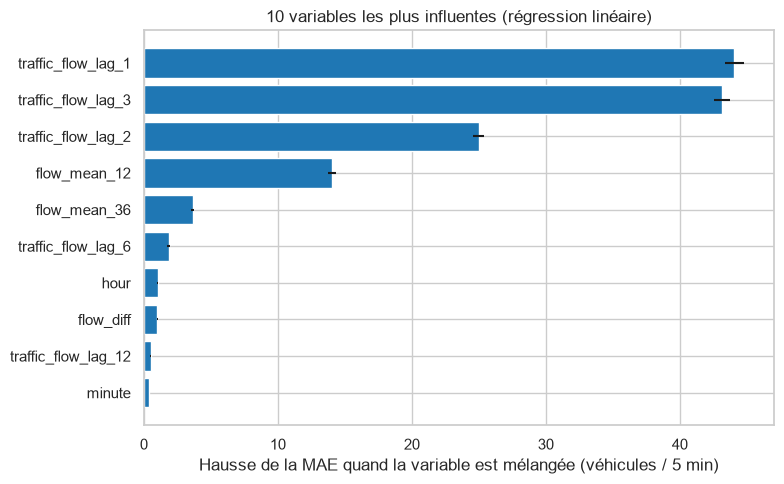

,variable,hausse_MAE,ecart_type
0,traffic_flow_lag_1,44.062,0.725
1,traffic_flow_lag_3,43.129,0.581
2,traffic_flow_lag_2,24.975,0.425
3,flow_mean_12,14.047,0.320
4,flow_mean_36,3.655,0.110
5,traffic_flow_lag_6,1.847,0.095
6,hour,1.015,0.032
7,flow_diff,1.000,0.026
8,traffic_flow_lag_12,0.493,0.062
9,minute,0.377,0.029


In [39]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(modeles["regression_lineaire"], X_val, y_val,
                             scoring="neg_mean_absolute_error", n_repeats=5,
                             random_state=SEED, n_jobs=1)
importance = (pd.DataFrame({"variable": COLONNES_ENTREE, "hausse_MAE": imp.importances_mean,
                            "ecart_type": imp.importances_std})
              .sort_values("hausse_MAE", ascending=False).reset_index(drop=True))

t = importance.head(10).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(t["variable"], t["hausse_MAE"], xerr=t["ecart_type"], color="tab:blue")
plt.xlabel("Hausse de la MAE quand la variable est mélangée (véhicules / 5 min)")
plt.title("10 variables les plus influentes (régression linéaire)")
plt.tight_layout()
plt.show()
importance.round(3)

**Observation :** le modèle repose presque entièrement sur l'historique du débit : cette famille représente environ **99 %** de l'importance cumulée, contre environ 1 % pour le calendrier (surtout l'heure). Les trois derniers retards (`lag_1`, `lag_2`, `lag_3`) et la moyenne de la dernière heure portent l'essentiel de la prédiction ; l'importance est répartie entre elles parce qu'elles sont très corrélées, ce qui interdit de lire le poids d'un retard isolé. La vitesse passée n'apporte quasiment rien, et la **météo n'a aucun effet mesurable** (température, vent, précipitations et état du ciel sont à zéro ou légèrement négatives, ce qui est du bruit). Cela confirme le constat des graphiques : le trafic des 5 prochaines minutes se déduit du trafic des minutes précédentes. Une conséquence pour la page 6 du dashboard : la météo saisie par l'utilisateur n'influencera pratiquement pas la prédiction.

## 11. Export et vérifications

Le modèle final est sauvegardé dans **un seul fichier** : `models/best_model.pkl`. Il contient toute la pipeline (variables cycliques, normalisation, encodage, régression linéaire, borne à 0) et accepte les **colonnes brutes** (`COLONNES_ENTREE`). Il ne se recharge que si le dossier racine du projet est dans `sys.path` (le fichier fait référence à `src.features`) et avec les mêmes versions de bibliothèques, enregistrées dans `models/model_info.json`.

Trois vérifications automatiques sont faites avant de livrer le fichier :
1. le modèle rechargé prédit exactement comme l'original ;
2. il se recharge et prédit **dans un processus Python séparé**, comme le fera le dashboard ;
3. une ligne d'entrée construite depuis l'historique brut par `construire_entree` (comme le fera le dashboard) est identique à celle de l'entraînement et donne la même prédiction.

In [40]:
import joblib, json, subprocess, io
from datetime import datetime

dossier_modeles, dossier_resultats = RACINE / "models", RACINE / "results"
dossier_modeles.mkdir(exist_ok=True)
dossier_resultats.mkdir(exist_ok=True)

chemin_modele = dossier_modeles / "best_model.pkl"
joblib.dump(modele_final, chemin_modele)

# Vérification 1 : rechargement dans le même processus
recharge = joblib.load(chemin_modele)
assert np.allclose(recharge.predict(X_test), pred_test), "le modèle rechargé prédit différemment"
print("1. Rechargement dans le même processus : OK")

# Vérification 2 : rechargement dans un processus Python séparé (comme le fera le dashboard)
ligne_exemple = X_test.iloc[[1000]]
attendu = float(modele_final.predict(ligne_exemple)[0])
script = ("import warnings; warnings.filterwarnings('ignore')\n"
          "import io, joblib, pandas as pd\n"
          "from src.features import COLONNES_ENTREE\n"
          "m = joblib.load('models/best_model.pkl')\n"
          f"x = pd.read_json(io.StringIO({ligne_exemple.to_json(orient='split')!r}), orient='split')\n"
          "print(float(m.predict(x[COLONNES_ENTREE])[0]))\n")
res = subprocess.run([sys.executable, "-c", script], cwd=RACINE, capture_output=True, text=True)
assert res.returncode == 0, res.stderr
obtenu = float(res.stdout.strip().splitlines()[-1])
assert abs(obtenu - attendu) < 1e-6, (obtenu, attendu)
print(f"2. Processus séparé : OK (prédiction {obtenu:.3f})")

# Vérification 3 : construire_entree depuis l'historique brut = ligne d'entraînement
full_modele = pd.concat([train, val, test], ignore_index=True)
pos = len(train) + len(val) + 1000
r = full_modele.iloc[pos]
e = construire_entree(full_modele.iloc[:pos], r["datetime"], r["temp_celsius"], r["wind_speed_kmh"],
                      r["precip_mm"], r["weather_condition"],
                      ferie=bool(r["holidays"]) and r["is_weekend"] == 0)
attendue = full_modele.iloc[[pos]][COLONNES_ENTREE].reset_index(drop=True)
pd.testing.assert_frame_equal(e.reset_index(drop=True), attendue, check_dtype=False)
assert abs(recharge.predict(e)[0] - recharge.predict(attendue)[0]) < 1e-9
print("3. construire_entree identique à la ligne d'entraînement : OK")

infer_final_ms = temps_inference_ms(recharge, X_test)
print(f"Temps d'inférence du modèle livré (1 ligne, pipeline complète) : {infer_final_ms:.1f} ms (objectif : < 1000 ms)")
print(f"Taille du fichier : {chemin_modele.stat().st_size / 1024:.0f} Ko")

1. Rechargement dans le même processus : OK
2. Processus séparé : OK (prédiction 257.239)
3. construire_entree identique à la ligne d'entraînement : OK
Temps d'inférence du modèle livré (1 ligne, pipeline complète) : 16.4 ms (objectif : < 1000 ms)
Taille du fichier : 6 Ko


### 11.2 Fichiers de résultats pour l'équipe

| Fichier | Contenu | Utilisateur |
|---|---|---|
| `results/metrics.csv` | tous les modèles et baselines (validation), score pondéré, métriques complémentaires | dashboard (page 3) |
| `results/metrics_test.csv` | résultat final sur le test | dashboard (pages 3 et 4) |
| `results/predictions_test.csv` | date, valeur réelle, prédiction du modèle final, persistance | dashboard (page 4) |
| `results/feature_importance.csv` | importance par permutation | dashboard (page 4) |
| `models/model_info.json` | colonnes d'entrée, conventions, performances, versions, seuils de niveaux | tous |

In [41]:
import sklearn
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Métriques complémentaires de tous les modèles et baselines (validation)
seuils = y_train.quantile([1/3, 2/3]).values       # seuils des niveaux de trafic : tiers du train
def niveau(debit):
    return np.digitize(np.asarray(debit), seuils)  # 0 = faible, 1 = moyen, 2 = élevé

niveau_vrai = niveau(y_val)
trafic_eleve = y_val.values > seuils[1]
mae_pers_val = np.abs(y_val.values - predictions_val["persistance"]).mean()

def metriques_complementaires(nom):
    p = np.asarray(predictions_val[nom])
    e = y_val.values - p
    npred = niveau(p)
    pr, rc, f1, _ = precision_recall_fscore_support(niveau_vrai, npred, average="macro", zero_division=0)
    return {"model": nom,
            "gain_vs_persistance_pct": (1 - np.abs(e).mean() / mae_pers_val) * 100,
            "WAPE_pct": np.abs(e).sum() / y_val.values.sum() * 100,
            "biais": e.mean(),
            "MAE_trafic_eleve": np.abs(e[trafic_eleve]).mean(),
            "accuracy_niveaux": accuracy_score(niveau_vrai, npred),
            "precision_niveaux": pr, "rappel_niveaux": rc, "F1_niveaux": f1}

complementaires = pd.DataFrame([metriques_complementaires(n) for n in predictions_val
                                if n != "moyenne_globale"])

# results/metrics.csv : tous les modèles et baselines (validation)
export = tableau.merge(scores[["rang", "score"]].rename(columns={"rang": "rang_grille", "score": "score_pondere"}),
                       left_on="model", right_index=True, how="left")
export = export.merge(complementaires, on="model", how="left")
export["retenu"] = export["model"] == "regression_lineaire"
colonnes_export = ["model", "type", "retenu", "MAE", "RMSE", "R2", "MAE_train", "gap_MAE", "blocs_gagnes",
                   "std_ratio", "train_time", "infer_time_ms", "rang_grille", "score_pondere",
                   "gain_vs_persistance_pct", "WAPE_pct", "biais", "MAE_trafic_eleve", "accuracy_niveaux",
                   "precision_niveaux", "rappel_niveaux", "F1_niveaux", "best_params"]
colonnes_export = [c for c in colonnes_export if c in export.columns]
export[colonnes_export].sort_values("MAE").to_csv(dossier_resultats / "metrics.csv", index=False)

# results/metrics_test.csv, predictions_test.csv, feature_importance.csv
resultats_test.to_csv(dossier_resultats / "metrics_test.csv", index=False)
pd.DataFrame({"datetime": test["datetime"].values, "y_true": y_test.values, "y_pred": pred_test,
              "y_persistance": pred_pers_test}).to_csv(dossier_resultats / "predictions_test.csv", index=False)
importance.to_csv(dossier_resultats / "feature_importance.csv", index=False)

# models/model_info.json
info = {
    "modele": "regression_lineaire", "fichier": "best_model.pkl",
    "description": "Prédit traffic_flow (véhicules par 5 min) à partir de l'historique récent, du calendrier et de la météo. "
                   "Pipeline complète à colonnes brutes, sortie bornée à 0.",
    "entrainement": "train + validation réunis ; régression linéaire sans hyperparamètre",
    "variables_entree": COLONNES_ENTREE,
    "conventions": {"week_day": "1 = lundi ... 7 = dimanche (isoweekday)",
                    "holidays": "1 pour un jour férié et pour tous les week-ends",
                    "pas_de_temps": "5 minutes",
                    "historique_minimum": HISTORIQUE_MIN,
                    "usage": "from src.features import construire_entree, COLONNES_ENTREE ; "
                             "joblib.load('models/best_model.pkl').predict(construire_entree(...))"},
    "performances_validation": {"MAE": float(mae_val_lr), "MAE_persistance": float(mae_val_pers)},
    "performances_test": {k: float(v) for k, v in resultats_test.iloc[0].drop("modèle").items()},
    "temps_inference_ms": round(infer_final_ms, 2),
    "seuils_niveaux_trafic": {"faible_jusqu_a": float(seuils[0]), "moyen_jusqu_a": float(seuils[1]),
                              "definition": "tiers du débit du train (véhicules par 5 min)"},
    "versions": {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
                 "scikit-learn": sklearn.__version__},
    "graine_aleatoire": SEED,
    "date_generation": datetime.now().isoformat(timespec="seconds"),
}
with open(dossier_modeles / "model_info.json", "w", encoding="utf-8") as f:
    json.dump(info, f, indent=2, ensure_ascii=False)

for nom in ["models/best_model.pkl", "models/model_info.json", "results/metrics.csv", "results/metrics_test.csv",
            "results/predictions_test.csv", "results/feature_importance.csv"]:
    print(f"{nom:34s} {(RACINE / nom).stat().st_size / 1024:8.1f} Ko")

models/best_model.pkl                   6.1 Ko
models/model_info.json                  1.9 Ko
results/metrics.csv                     4.1 Ko
results/metrics_test.csv                0.4 Ko
results/predictions_test.csv          251.3 Ko
results/feature_importance.csv          1.0 Ko


In [42]:
recap = pd.DataFrame({
    "Validation": [tableau.loc[tableau["model"] == m, "MAE"].iloc[0]
                   for m in ["regression_lineaire", "persistance", "moyenne_par_heure"]],
    "Test": [resultats_test.iloc[0]["MAE"], resultats_test.iloc[1]["MAE"], resultats_test.iloc[2]["MAE"]],
}, index=["regression_lineaire (retenue)", "persistance", "moyenne_par_heure"]).round(2)
recap.index.name = "MAE (véhicules / 5 min)"
recap

,Validation,Test
MAE (véhicules / 5 min),,
regression_lineaire (retenue),19.41,19.99
persistance,22.47,23.01
moyenne_par_heure,51.57,45.33


## 12. Conclusion

### Démarche

Nous avons comparé **8 modèles** (régression linéaire, Decision Tree, Random Forest, KNN, SVM, XGBoost, LightGBM, MLP) à **3 baselines** (persistance, moyenne par heure, moyenne globale) pour prédire le débit des 5 prochaines minutes. La méthode est la même pour tous : découpage chronologique 70 / 15 / 15, variables d'historique calculées sur le passé seul, pipeline de prétraitement ajustée sur le train, réglage par validation croisée temporelle, comparaison sur la validation, sélection par la grille pondérée du cahier des charges avec analyse de sensibilité, puis évaluation unique sur le test après réentraînement sur train et validation.

### Résultats

| | Validation | Test |
|---|---|---|
| Régression linéaire (modèle retenu) | MAE 19,42 | MAE **19,99**, R² 0,974 |
| Persistance (référence) | MAE 22,47 | MAE 23,01 |
| Moyenne par heure | MAE 51,57 | MAE 45,33 |
| Gain de la régression linéaire sur la persistance | 13,6 % | **13,1 %** |

Sur le test, l'écart de 3,02 véhicules avec la persistance est statistiquement fiable (intervalle de confiance à 95 % de −3,35 à −2,75) et régulier : le modèle bat la persistance dans les 6 blocs du test. L'erreur représente environ 4,9 % du trafic.

### Ce que nous retenons

1. **Le trafic des 5 prochaines minutes se déduit presque entièrement du trafic des minutes précédentes** : corrélation de 0,98 avec le débit 5 minutes plus tôt, et environ 99 % de l'importance du modèle portée par l'historique du débit. La persistance est donc une référence très difficile à battre, et le gain réel des modèles est modeste (de l'ordre de 13 à 17 %).
2. **La régression linéaire est retenue** parce qu'elle est première de la grille pondérée dans les quatre pondérations testées. Elle est à moins de 3 % de la meilleure MAE, bat la persistance dans tous les blocs, ne surapprend pas et reste le modèle le plus simple.
3. **Le classement est serré.** LightGBM a la MAE de validation la plus basse (18,87 contre 19,42) et l'écart avec la régression linéaire est statistiquement réel, mais il est faible en pratique (0,54 véhicule, soit 2,8 %, environ 0,1 % du débit moyen). Les deux modèles sont donc proches ; LightGBM reste une alternative légèrement plus précise si l'équipe préfère la précision à la simplicité.
4. **Les variables de calendrier comptent peu, la météo pas du tout** : l'historique du débit représente environ 99 % de l'importance cumulée, le calendrier environ 1 %, et la température, le vent, les précipitations et l'état du ciel n'ont aucun effet mesurable.
5. **Le modèle est livré prêt à l'emploi** : un seul fichier (`models/best_model.pkl`), pipeline incluse, colonnes brutes en entrée, sortie bornée à 0, vérifié dans un processus Python séparé et de bout en bout avec `construire_entree`. Son temps d'inférence est de l'ordre de quelques millisecondes, très en dessous de la limite d'une seconde.

### Limites

- **Quatre mois de données, un seul tronçon, un changement de régime** (confinement de 2020) : le débit moyen passe d'environ 502 en février à 333 en avril. Les scores ne représentent pas une année normale.
- **Validation et test de 18 jours chacun.** Le test avait déjà été consulté dans une version précédente de ce notebook ; il n'est pas vierge.
- **Un seul horizon** : 5 minutes. Le choix d'un modèle linéaire vaut pour cet horizon ; un modèle non linéaire peut devenir plus avantageux pour des horizons plus longs (observation exploratoire, non démontrée dans ce notebook).
- **Réglages limités** : grilles d'hyperparamètres réduites ; le SVM n'est pas réglé et n'utilise qu'un tiers du train, son résultat n'est donc pas strictement comparable.
- **Temps mesurés sur une machine** : leur bruit peut faire basculer un classement serré ; la note d'interprétabilité est un jugement et les poids de la grille sont une convention.
- **Les niveaux de trafic (faible / moyen / élevé) décrivent un volume, pas la congestion** : un débit faible peut aussi traduire une route saturée. Sur ces trois niveaux, l'avantage sur la persistance est faible (F1 macro de 0,903 contre 0,889 en validation).
- **Pas de découpage par voie** : le jeu de données ne contient qu'une série, alors que le module de décision attend un trafic par voie. Une hypothèse de répartition reste à définir avec la simulation.

### Pistes d'amélioration

- Tester d'autres horizons (15 minutes, 1 heure) et régler les hyperparamètres horizon par horizon.
- Ajouter un indicateur du niveau récent du trafic (par exemple le débit de la veille à la même heure) pour un modèle sans historique immédiat, utile à la page de prédiction interactive.
- Régression par quantiles pour obtenir des intervalles de prédiction, utiles pour fixer les durées minimale et maximale de vert.
- Prédire aussi la vitesse, qui décrit mieux la congestion que le débit.
- Évaluer en origines glissantes sur une période plus longue et plusieurs capteurs.